2026.10.28 一致性修订：请 Restart Kernel & Run All。初始化会验证当前 embedding→特征→预测→概率；旧 niche 缓存不再复用，旧图输出已清空。Deployment 最佳模型用法保持不变。


# Lung Incomplete_Cases — UNI2 A2 best_mlp

All **20** Xenium Incomplete_Cases. StarDist-all maps only; no TLS / SRI / TNI.
The first five are the best matched-cell **L2 macro AUROC** when a UNI2 rank table exists.
Slides without matched GT stay at the end.

Checkpoint: `data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt` (fold 1).

The UNI notebook `Pred_visual_lung_incomplete.ipynb` still reads `pred_all_spatial/incomplete_lung/`.

```bash
CUDA_DEVICE=0 bash code/External_val/Lung_Incomplete/demo_uni2.sh predict
```


In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.28, explicit checkout override / Farm 可设 HIST2PHENO_REPO
import os
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
os.environ["UNI2_CKPT"] = str(
    REPO
    / "data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42"
    / "cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt"
)
STAR_PROB_MIN = 0.0  # 2026.10.28, set above 0 to store a separate _probXX folder
import os as _prob_os
_prob_os.environ["STAR_PROB_MIN"] = "0" if float(STAR_PROB_MIN) <= 0 else f"{float(STAR_PROB_MIN):.2f}"
os.environ["UNI2_PRED_DIRNAME"] = "pred_uni2_A2_bestmlp_paired_v2_seed42"
sys.path.insert(0, str(REPO / "code" / "Hist2Pheno_pkg"))
sys.path.insert(0, str(REPO / "code" / "External_val"))

import unlabeled_external as ue

COHORT = "Lung_Incomplete"
EMBEDDER = "uni2"
SAVE_FIGURES = True
FIGSIZE = (17.2, 12.5)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 2.0

print("checkpoint", ue._ckpt(EMBEDDER))
cov = ue.coverage(COHORT, EMBEDDER)
rank = ue.rank_lung_incomplete(compute=False, embedder=EMBEDDER)
samples = ue.viz_samples(COHORT, embedder=EMBEDDER)
top5 = samples[:5]
rest = samples[5:]
print(f"{COHORT}: {len(cov)} slides; plot order {len(samples)} (top 5 first)")
print("top5", top5)
print("rest", rest)
if rank.empty:
    print("ranks missing — run: bash code/External_val/Lung_Incomplete/demo_uni2.sh rank")
else:
    cols = [c for c in (
        "rank_ds", "n_ds", "sample", "n_matched",
        "macro_auc_L1", "macro_auc_L12", "macro_auc_L2", "acc_L2",
    ) if c in rank.columns]
    display(Markdown("### Matched-cell ranks (L2 AUROC). Top 5 are plotted first."))
    display(rank[cols])

# 2026.10.28, mandatory current-input preflight / 后续直接读 h5ad 的图表也不得绕过上游
import os as _pipeline_os
_pipeline_os.environ["STAR_PROB_MIN"] = str(globals().get("STAR_PROB_MIN", 0.0))
ue.cmd_predict(COHORT, samples, cuda_device=_pipeline_os.environ.get("CUDA_DEVICE", "0"),
               force=False, allow_cpu=True, embedder=EMBEDDER)


checkpoint /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt
Lung_Incomplete: 20 slides; plot order 20 (top 5 first)
top5 ['VUILD141MA', 'TILD117MA2', 'VUILD58MA', 'TILD113LA', 'TILD299MA']
rest ['TILD080LA', 'TILD315MA', 'VUILD49LA', 'VUILD142MA', 'TILD130LA', 'TILD111LA', 'TILD167LA', 'VUILD104MA2', 'TILD028LA', 'VUHD090', 'VUHD049', 'TILD049MA', 'VUILD105MA1', 'VUHD038', 'VUILD48LA1']
ranks missing — run: bash code/External_val/Lung_Incomplete/demo_uni2.sh rank
Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded


## TILD113LA, VUILD105MA1

### TILD113LA

Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_bestmlp_paired_v2_seed42/unlabel/Lung_Incomplete/figures/TILD113LA_spatial_L1_L12_L2.pdf


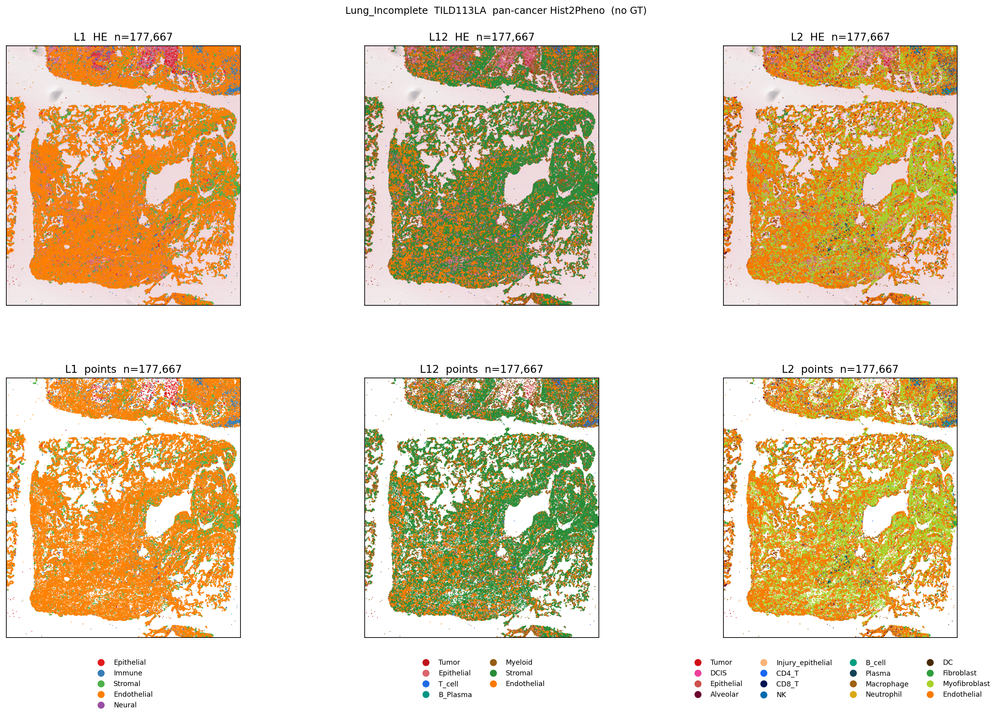

### VUILD105MA1

Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_bestmlp_paired_v2_seed42/unlabel/Lung_Incomplete/figures/VUILD105MA1_spatial_L1_L12_L2.pdf


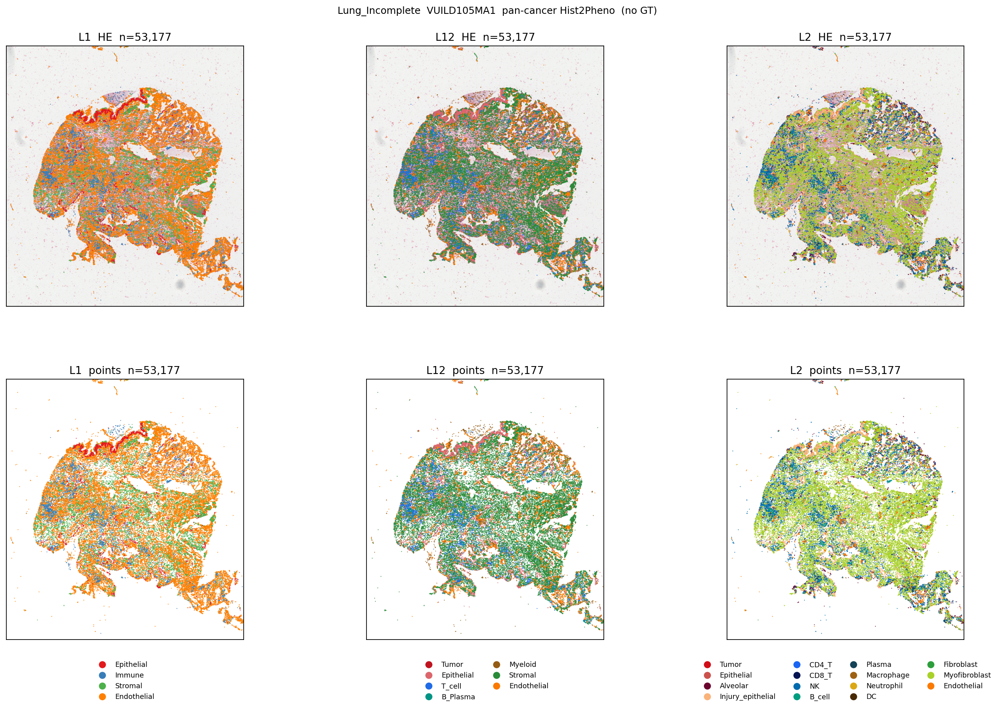

In [10]:
focus = ["TILD113LA", "VUILD105MA1"]


def _rank_title(sample: str) -> str:
    if rank.empty or "sample" not in rank.columns:
        return sample
    hit = rank.loc[rank["sample"].astype(str) == str(sample)]
    if hit.empty:
        return f"{sample}  (no matched GT)"
    rank_ds = hit.iloc[0]["rank_ds"]
    if rank_ds != rank_ds:
        return f"{sample}  (no matched GT)"
    r = hit.iloc[0]
    return (
        f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
        f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
    )


def _draw(sample: str) -> None:
    pred = ue.pred_h5ad(ue._cohort(COHORT, EMBEDDER), sample)
    display(Markdown(f"### {_rank_title(sample)}"))
    if not pred.is_file():
        print("missing pred", sample, "— run demo_uni2.sh predict")
        return
    figs = ue.plot_spatial(
        COHORT,
        [sample],
        embedder=EMBEDDER,
        save=SAVE_FIGURES,
        figsize=FIGSIZE,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        he_max_side=HE_MAX_SIDE,
        marker_px=MARKER_PX,
    )
    for fig in figs:
        display(fig)
        plt.close(fig)


display(Markdown("## TILD113LA, VUILD105MA1"))
for sample in focus:
    _draw(sample)


In [11]:
# from matplotlib.lines import Line2D
# import anndata as ad

# # One L1 / L12 / L2 legend per sample (the two spatial maps above).
# plt.rcParams["pdf.fonttype"] = 42
# plt.rcParams["ps.fonttype"] = 42
# plt.rcParams["pdf.use14corefonts"] = True

# cohort = ue._cohort(COHORT, EMBEDDER)
# palettes = ue._palettes()
# FIG_DIR = cohort.pred_parent / "figures"
# FIG_DIR.mkdir(parents=True, exist_ok=True)


# def _legend_handles(palette, names):
#     return [
#         Line2D(
#             [0],
#             [0],
#             linestyle="none",
#             marker="o",
#             markersize=8,
#             markerfacecolor=palette.get(n, (0.5, 0.5, 0.5, 1))[:3],
#             markeredgecolor="none",
#             label=n,
#         )
#         for n in names
#     ]


# def _present_names(adata, head):
#     palette = palettes[head]
#     seen = set(map(str, adata.obs[ue.OBS_COL[head]].tolist()))
#     names = [n for n in palette if n in seen]
#     names += sorted(seen - set(names))
#     return names


# for sample in focus:
#     adata = ad.read_h5ad(ue.pred_h5ad(cohort, sample))
#     display(Markdown(f"### {sample}  legend"))
#     fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.6), dpi=200)
#     for ax, head in zip(axes, ue.HEADS):
#         names = _present_names(adata, head)
#         ax.set_axis_off()
#         ax.legend(
#             handles=_legend_handles(palettes[head], names),
#             loc="center",
#             frameon=False,
#             ncol=1 if len(names) <= 6 else 2,
#             fontsize=8,
#             handlelength=0.8,
#             handletextpad=0.45,
#             columnspacing=1.0,
#             labelspacing=0.35,
#             borderaxespad=0.0,
#             title=head,
#             title_fontsize=10,
#         )
#     fig.suptitle(f"{sample}   predicted classes", fontsize=11, y=0.98)
#     fig.tight_layout()
#     stem = FIG_DIR / f"{sample}_legend"
#     fig.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight", facecolor="white")
#     fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
#     print(stem.with_suffix(".pdf"))
#     display(fig)
#     plt.close(fig)

#     # Separate L1 / L12 / L2 PDFs for panel assembly.
#     for head in ue.HEADS:
#         names = _present_names(adata, head)
#         ncol = 1 if len(names) <= 8 else 2
#         fig_h, ax = plt.subplots(figsize=(2.8 * ncol, 0.38 * ((len(names) + ncol - 1) // ncol) + 0.7), dpi=200)
#         ax.set_axis_off()
#         ax.legend(
#             handles=_legend_handles(palettes[head], names),
#             loc="center",
#             frameon=False,
#             ncol=ncol,
#             fontsize=8,
#             handlelength=0.8,
#             handletextpad=0.45,
#             columnspacing=1.0,
#             labelspacing=0.35,
#             borderaxespad=0.0,
#             title=head,
#             title_fontsize=10,
#         )
#         stem_h = FIG_DIR / f"{sample}_legend_{head}"
#         fig_h.savefig(stem_h.with_suffix(".png"), dpi=300, bbox_inches="tight", facecolor="white")
#         fig_h.savefig(stem_h.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
#         print(stem_h.with_suffix(".pdf"))
#         plt.close(fig_h)


### TILD113LA  zoom  Plasma-rich lymphoid island  [7800:10200]×[13000:15400]  510×510 µm

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_bestmlp_paired_v2_seed42/unlabel/Lung_Incomplete/figures/TILD113LA_ROI_HE.pdf


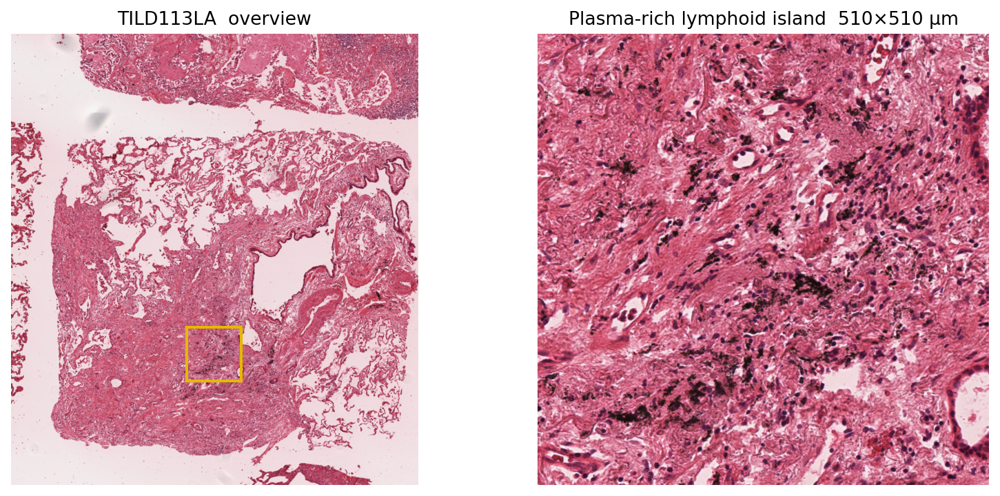

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_bestmlp_paired_v2_seed42/unlabel/Lung_Incomplete/figures/TILD113LA_ROI_spatial_L1_L12_L2.pdf


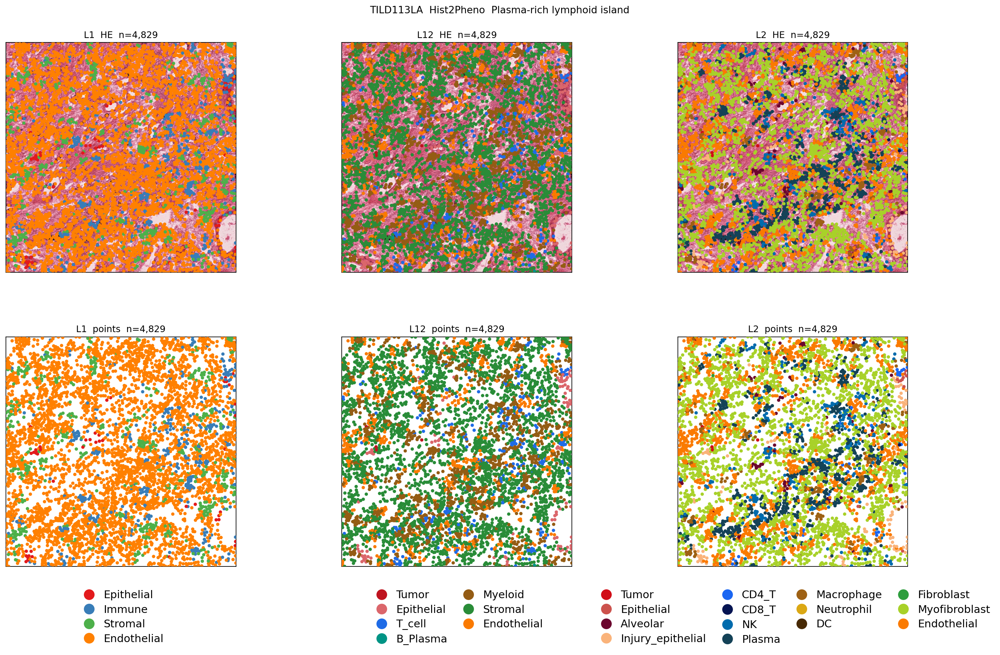

### VUILD105MA1  zoom  Airway epithelium + myofibroblast wall  [7400:11000]×[3400:6400]  765×638 µm

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_bestmlp_paired_v2_seed42/unlabel/Lung_Incomplete/figures/VUILD105MA1_ROI_HE.pdf


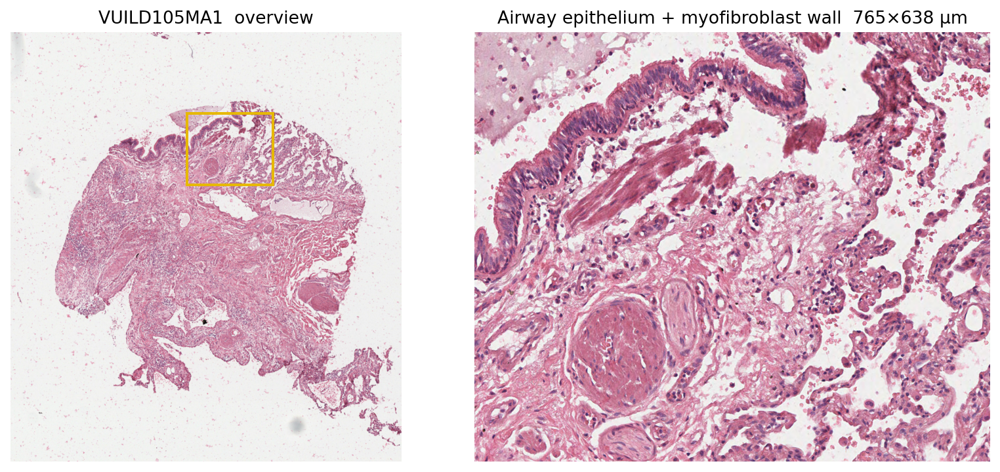

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_bestmlp_paired_v2_seed42/unlabel/Lung_Incomplete/figures/VUILD105MA1_ROI_spatial_L1_L12_L2.pdf


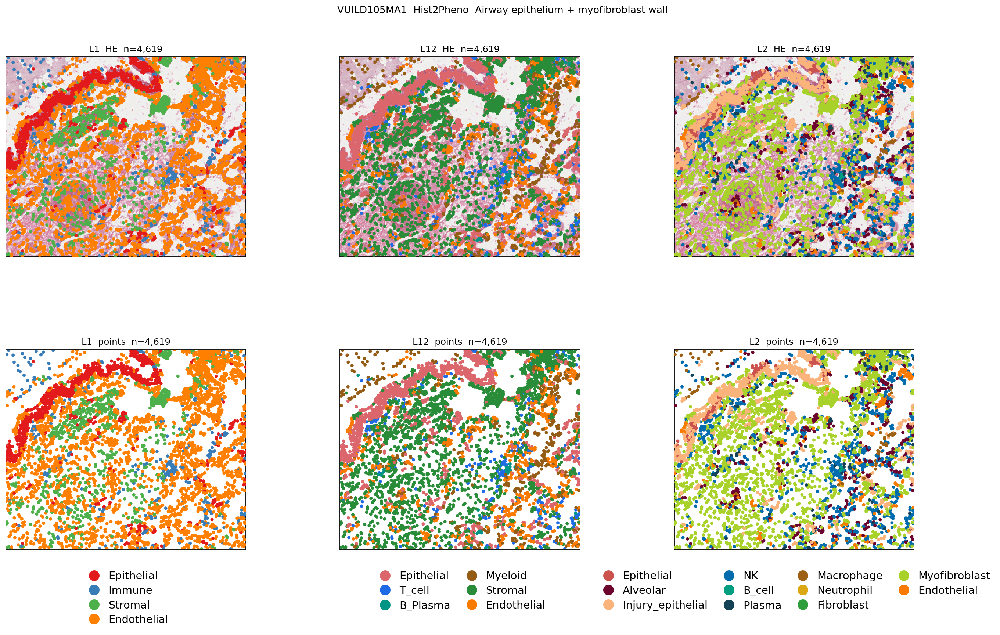

In [12]:
import anndata as ad
from matplotlib.patches import Rectangle
from panel_figures import crop_he_rectangle, plot_roi_pred_spatial

# TILD113LA ImageJ tag is 4.705882 px/µm; VUILD105MA1 uses the same Xenium-lung HE scale.
PX_PER_UM = 4705882 / 1_000_000
# ~510 µm Plasma-rich island; ~765 × 638 µm airway epithelium + fibrotic wall.
ROIS = {
    "TILD113LA": {
        "xy": (7800, 13000, 10200, 15400),
        "note": "Plasma-rich lymphoid island",
    },
    "VUILD105MA1": {
        "xy": (7400, 3400, 11000, 6400),
        "note": "Airway epithelium + myofibroblast wall",
    },
}

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["pdf.use14corefonts"] = True

cohort = ue._cohort(COHORT, EMBEDDER)
palettes = ue._palettes()
FIG_DIR = cohort.pred_parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for sample, spec in ROIS.items():
    x0, y0, x1, y1 = spec["xy"]
    he = ue.he_path(cohort, sample)
    adata = ad.read_h5ad(ue.pred_h5ad(cohort, sample))
    thumb, fw, fh = ue._he_thumbnail(he, HE_MAX_SIDE)
    w_um = (x1 - x0) / PX_PER_UM
    h_um = (y1 - y0) / PX_PER_UM
    display(Markdown(
        f"### {sample}  zoom  {spec['note']}  "
        f"[{x0}:{x1}]×[{y0}:{y1}]  {w_um:.0f}×{h_um:.0f} µm"
    ))

    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.6), dpi=DPI)
    axes[0].imshow(thumb, extent=(0, fw, fh, 0), interpolation="bilinear")
    axes[0].add_patch(
        Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#E6B800", lw=1.8)
    )
    axes[0].set_title(f"{sample}  overview")
    axes[0].set_axis_off()
    axes[1].imshow(crop_he_rectangle(he, x0, y0, x1, y1))
    axes[1].set_title(f"{spec['note']}  {w_um:.0f}×{h_um:.0f} µm")
    axes[1].set_axis_off()
    fig.tight_layout()
    stem = FIG_DIR / f"{sample}_ROI_HE"
    if SAVE_FIGURES:
        fig.savefig(stem.with_suffix(".png"), dpi=SAVE_DPI, bbox_inches="tight", facecolor="white")
        fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
        print(stem.with_suffix(".pdf"))
    display(fig)
    plt.close(fig)

    fig_z, _ = plot_roi_pred_spatial(
        adata,
        he,
        x0=x0,
        y0=y0,
        x1=x1,
        y1=y1,
        palettes=palettes,
        marker_px=2*4.5,
        dpi=DPI,
        figsize=FIGSIZE,
        title=f"{sample}  Hist2Pheno  {spec['note']}",
        save_path=(FIG_DIR / f"{sample}_ROI_spatial_L1_L12_L2.png") if SAVE_FIGURES else None,
        save_dpi=SAVE_DPI,
    )
    if SAVE_FIGURES:
        pdf = FIG_DIR / f"{sample}_ROI_spatial_L1_L12_L2.pdf"
        fig_z.savefig(pdf, bbox_inches="tight", facecolor="white")
        print(pdf)
    display(fig_z)
    plt.close(fig_z)


In [ ]:
import importlib
import panel_figures
importlib.reload(panel_figures)
from panel_figures import crop_he_rectangle, load_stardist_polys, plot_stardist_roi_boundary

STAR_ROOT = REPO / "data/Xemium/LUNG/StarDist_Segment"
# VUILD105MA1 has no full-slide polys. Its pickle is this ROI only
# (2D_versatile_he, prob 0.01, nms 0.3), coordinates in H&E pixels.

for sample, spec in ROIS.items():
    x0, y0, x1, y1 = spec["xy"]
    folder = STAR_ROOT / sample
    hits = sorted(folder.glob("polys_prob*.pckl")) if folder.is_dir() else []
    if not hits:
        print(f"{sample}: no polys_prob*.pckl in {folder}")
        continue
    coord, points = load_stardist_polys(hits[-1])
    he = ue.he_path(cohort, sample)
    crop = crop_he_rectangle(he, x0, y0, x1, y1)
    stem = FIG_DIR / f"{sample}_ROI_stardist_nuclei_boundary"
    fig, n_in = plot_stardist_roi_boundary(
        crop,
        coord,
        points,
        x0,
        y0,
        x1,
        y1,
        px_per_um=PX_PER_UM,
        outline="#3DDC00",
        center="#F0A202",
        dpi=DPI,
        save_path=stem if SAVE_FIGURES else None,
        save_dpi=SAVE_DPI,
    )
    display(Markdown(
        f"### {sample}  StarDist nuclei + boundary  {spec['note']}  "
        f"n={n_in:,}  ({hits[-1].name})"
    ))
    if n_in == 0:
        print(f"{sample}: no StarDist nuclei inside this ROI")
    elif SAVE_FIGURES:
        print(stem.with_suffix(".pdf"))
    display(fig)
    plt.close(fig)


In [14]:
# focus = ["TILD113LA", "VUILD105MA1", "VUILD104MA2"]


# def _rank_title(sample: str) -> str:
#     if rank.empty or "sample" not in rank.columns:
#         return sample
#     hit = rank.loc[rank["sample"].astype(str) == str(sample)]
#     if hit.empty:
#         return f"{sample}  (no matched GT)"
#     rank_ds = hit.iloc[0]["rank_ds"]
#     if rank_ds != rank_ds:
#         return f"{sample}  (no matched GT)"
#     r = hit.iloc[0]
#     return (
#         f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
#         f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
#     )


# def _draw(sample: str) -> None:
#     pred = ue.pred_h5ad(ue._cohort(COHORT, EMBEDDER), sample)
#     display(Markdown(f"### {_rank_title(sample)}"))
#     if not pred.is_file():
#         print("missing pred", sample, "— run demo_uni2.sh predict")
#         return
#     figs = ue.plot_spatial(
#         COHORT,
#         [sample],
#         embedder=EMBEDDER,
#         save=SAVE_FIGURES,
#         figsize=FIGSIZE,
#         dpi=DPI,
#         save_dpi=SAVE_DPI,
#         he_max_side=HE_MAX_SIDE,
#         marker_px=MARKER_PX,
#     )
#     for fig in figs:
#         display(fig)
#         plt.close(fig)


# display(Markdown("## TILD113LA, VUILD105MA1, VUILD104MA2"))
# for sample in focus:
#     _draw(sample)


In [15]:
# def _rank_title(sample: str) -> str:
#     if rank.empty or "sample" not in rank.columns:
#         return sample
#     hit = rank.loc[rank["sample"].astype(str) == str(sample)]
#     if hit.empty:
#         return f"{sample}  (no matched GT)"
#     rank_ds = hit.iloc[0]["rank_ds"]
#     if rank_ds != rank_ds:
#         return f"{sample}  (no matched GT)"
#     r = hit.iloc[0]
#     return (
#         f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
#         f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
#     )


# def _draw(sample: str) -> None:
#     pred = ue.pred_h5ad(ue._cohort(COHORT, EMBEDDER), sample)
#     display(Markdown(f"### {_rank_title(sample)}"))
#     if not pred.is_file():
#         print("missing pred", sample, "— run demo_uni2.sh predict")
#         return
#     figs = ue.plot_spatial(
#         COHORT,
#         [sample],
#         embedder=EMBEDDER,
#         save=SAVE_FIGURES,
#         figsize=FIGSIZE,
#         dpi=DPI,
#         save_dpi=SAVE_DPI,
#         he_max_side=HE_MAX_SIDE,
#         marker_px=MARKER_PX,
#     )
#     for fig in figs:
#         display(fig)
#         plt.close(fig)


# display(Markdown("## Top 5 by matched L2 AUROC"))
# for sample in top5:
#     _draw(sample)

# display(Markdown("## Remaining Incomplete_Cases"))
# for sample in rest:
#     _draw(sample)



In [16]:
# display(Markdown("## Predicted composition — top 5"))
# if top5:
#     figs = ue.plot_composition(COHORT, top5, embedder=EMBEDDER, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
#     for fig in figs:
#         display(fig)
#         plt.close(fig)

# display(Markdown("## Predicted composition — remaining"))
# if rest:
#     figs = ue.plot_composition(COHORT, rest, embedder=EMBEDDER, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
#     for fig in figs:
#         display(fig)
#         plt.close(fig)
